# Editing and arranging plots

Often, you will want to compare several plots at once. You can arrange plots in rows and columns using `par()`.



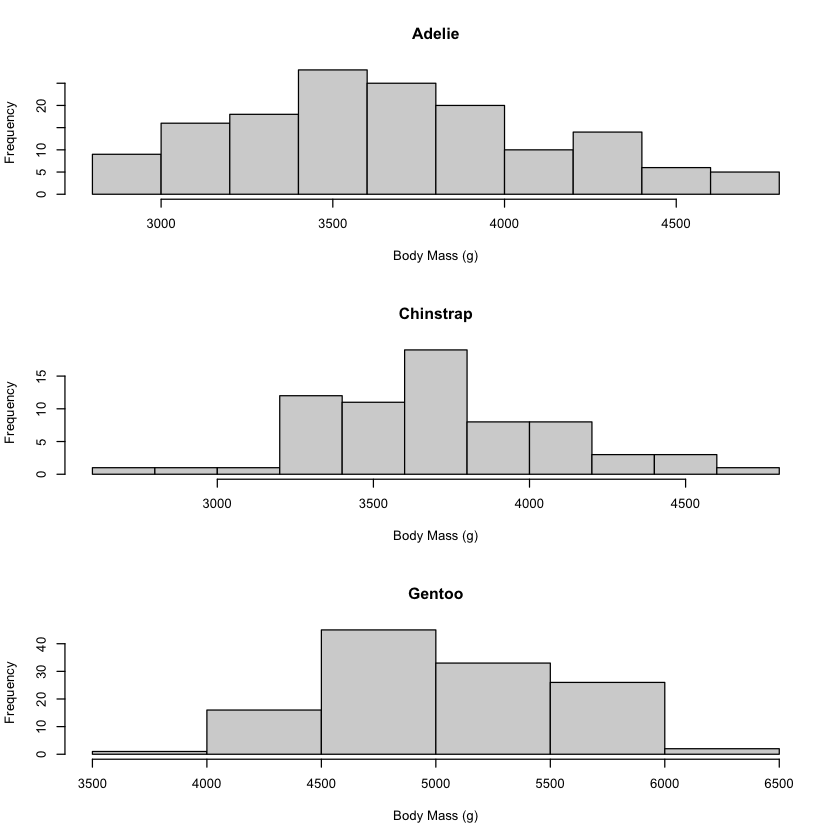

In [1]:
par(mfrow=c(3,1))

hist(penguins$body_mass[penguins$species=="Adelie"],
    main = "Adelie", xlab = "Body Mass (g)")

hist(penguins$body_mass[penguins$species=="Chinstrap"],
    main = "Chinstrap", xlab = "Body Mass (g)")
    
hist(penguins$body_mass[penguins$species=="Gentoo"],
    main = "Gentoo", xlab = "Body Mass (g)")

The `par()` function sets graphical parameters. The `mfrow` argument specifies the number of rows and columns used to arrange plots. It takes a vector in the form:

```r
par(mfrow = c(rows, columns))
```

For example, a two-row by two-column layout would use:

```r
par(mfrow = c(2, 2))
```


## Keeping axis scales consistent

The histograms above show body mass for each penguin species. To compare their distributions fairly, it helps to use the same axis limits. Otherwise, R may choose different scales for each plot.

Use `xlim` to set the lower and upper limits of the x-axis:


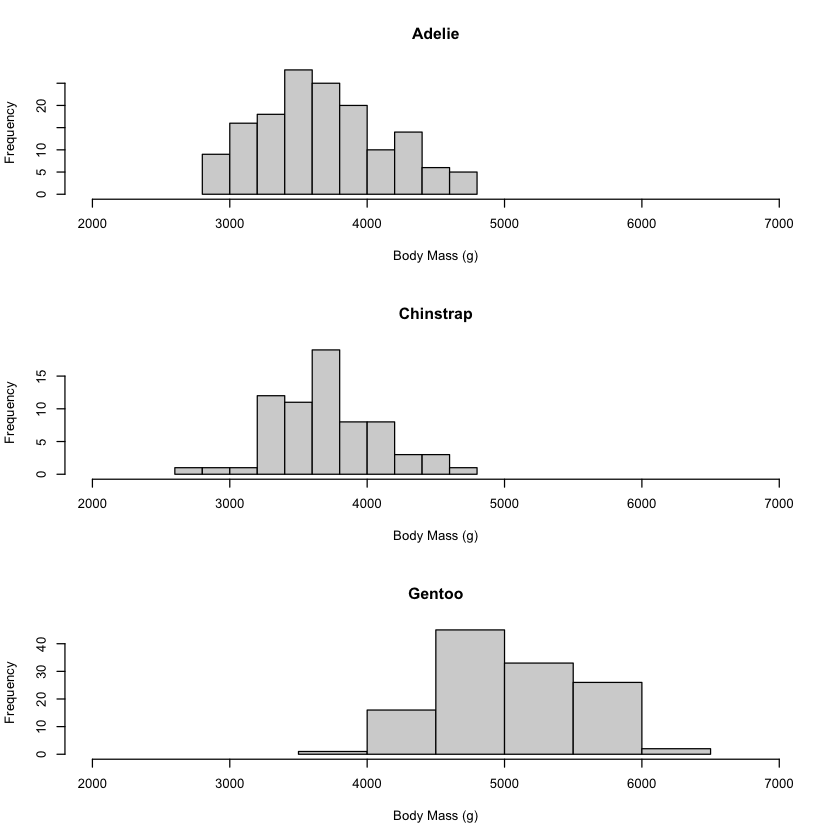

In [5]:
par(mfrow = c(3,1))

hist(penguins$body_mass[penguins$species=="Adelie"],
    main = "Adelie", xlab = "Body Mass (g)", xlim = c(2000,7000))

hist(penguins$body_mass[penguins$species=="Chinstrap"],
    main = "Chinstrap", xlab = "Body Mass (g)", xlim = c(2000,7000))
    
hist(penguins$body_mass[penguins$species=="Gentoo"],
    main = "Gentoo", xlab = "Body Mass (g)", xlim = c(2000,7000))


Using consistent `xlim` and `ylim` values is particularly important when comparing plots side by side.

## Resetting graphical settings

Changes made with `par()` remain active for later plots. For example, after running:

```r
par(mfrow = c(3, 1))
```

new plots will continue to use a three-row layout until you change the setting.

You can reset to a single plot layout with:

```r
par(mfrow = c(1, 1))
```

## Colours

Most plotting functions have a `col` argument that controls the colours used in a plot. You can use recognised colour names, such as `"blue"`, `"lightpink"`, or `"darkgreen"`. Rstudio will highlight the text in the appropriate colour if it is a recognised name.

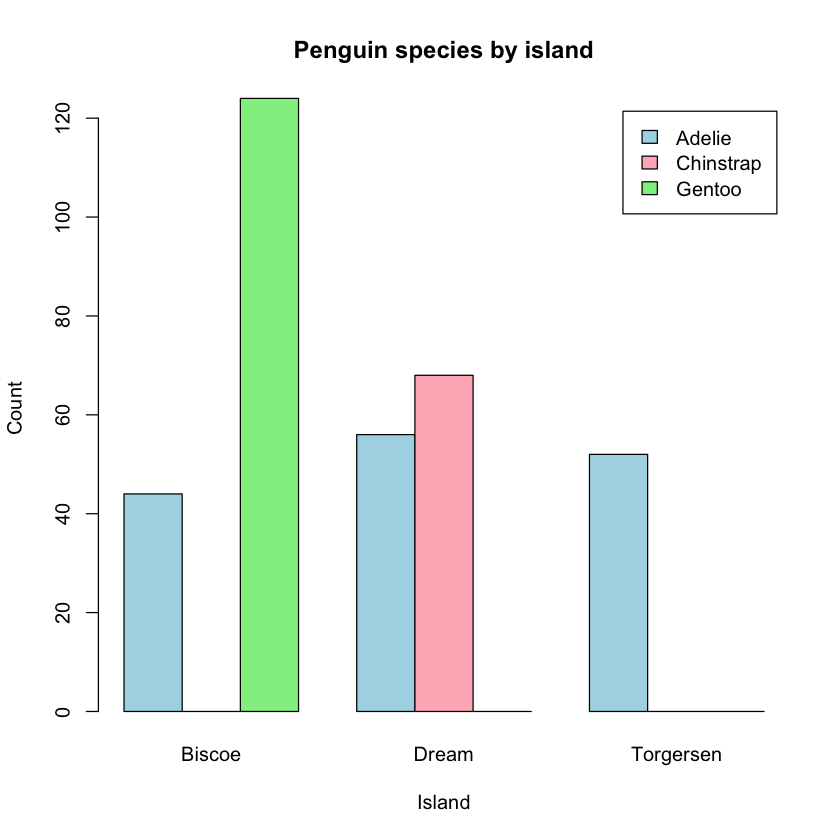

In [3]:
barplot(table(penguins$species,penguins$island), 
    main = "Penguin species by island", 
    xlab = "Island", 
    ylab = "Count", 
    col = c("lightblue", "lightpink", "lightgreen"), 
    legend.text = TRUE,
    beside = TRUE)

Alternatively you can specify colours using RGB values or hexadecimal codes. The University of Manchester's official colour palette is Purple, Yellow and Grey with specified RGB values:
* Purple (109, 0, 157)
* Yellow (255, 204, 51)
* Grey (149, 149, 151)

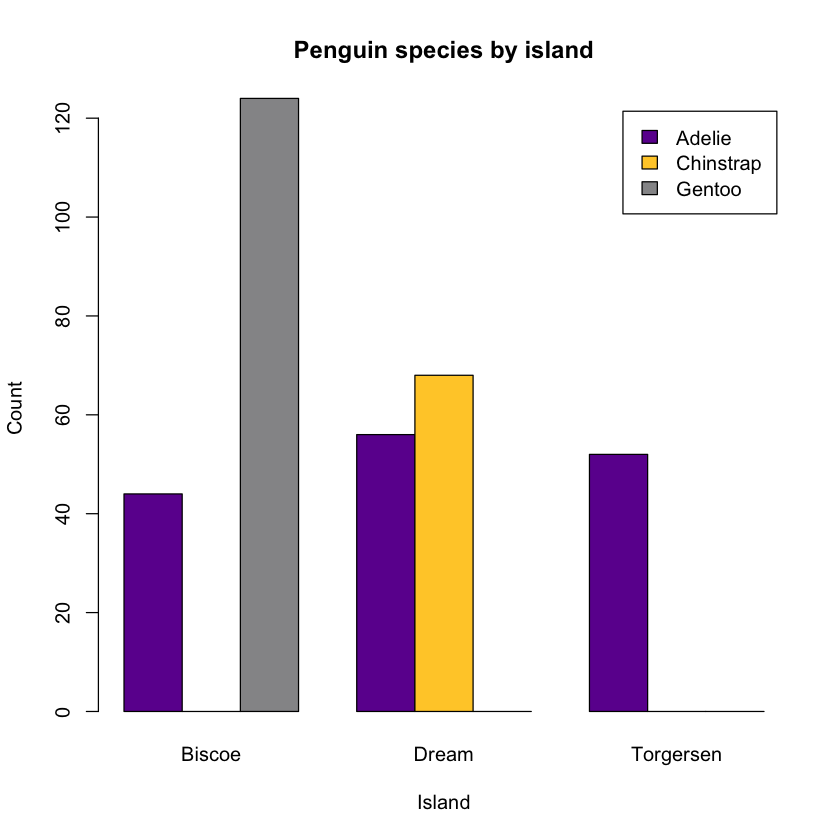

In [4]:
uomP <- rgb(109, 0, 157,maxColorValue = 255)
uomY <- rgb(255, 204, 51,maxColorValue = 255)
uomG <- rgb(149, 149, 151,maxColorValue = 255)


barplot(
  table(penguins$species, penguins$island),
  main = "Penguin species by island",
  xlab = "Island",
  ylab = "Count",
  col = c(uomP, uomY, uomG),
  legend.text = TRUE,
  beside = TRUE
)

The `beside` argument controls how the bars are arranged:

- `beside = TRUE` places the species bars side by side for each island.
- `beside = FALSE` stacks the species bars on top of one another. This is the default.

You can also assign colours automatically using a factor. For example, `species` is a factor with three levels, so R uses a different palette colour for each species:

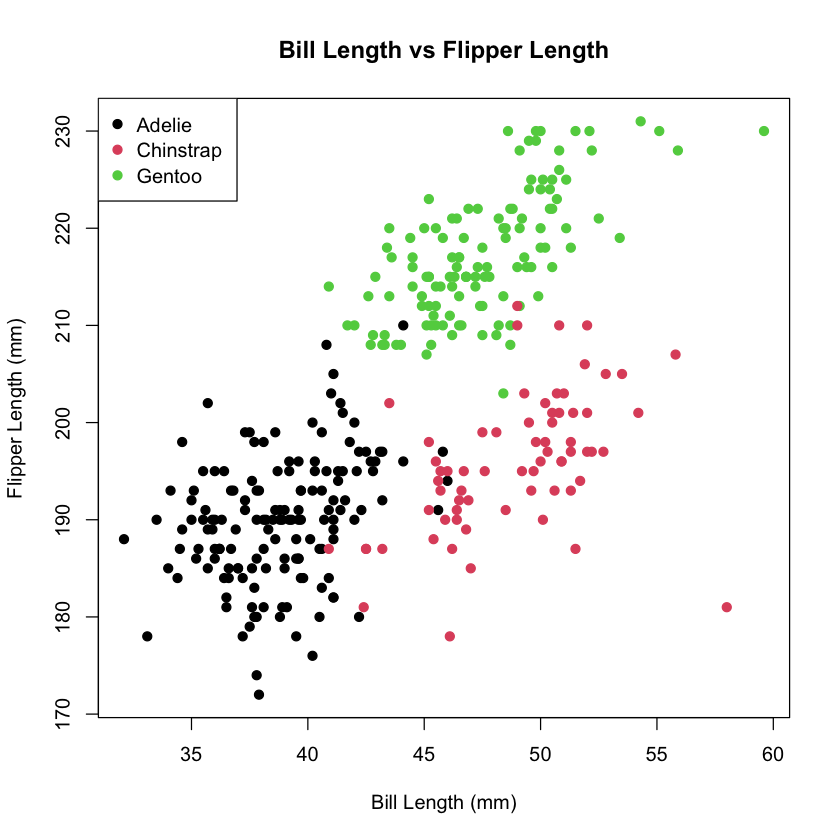

In [34]:
plot(penguins$bill_len,
    penguins$flipper_len,
    main = "Bill Length vs Flipper Length",
    xlab = "Bill Length (mm)",
    ylab = "Flipper Length (mm)",
    col = penguins$species,
    pch = 19)

legend("topleft", legend = levels(penguins$species), col = 1:3, pch = 19)

Factors are stored internally as integer codes. In this example, the three levels of `species` correspond to the values `1`, `2`, and `3`, and R uses the first three colours from the active palette.

The `legend()` function adds a legend to an existing plot.

````{tip}
You can use palettes other than the default. It is good practice to choose accessible colours that remain distinguishable for people with colour-vision differences.

The Okabe-Ito palette is a widely used accessible option:

```r
palette(palette.colors(palette = "Okabe-Ito"))
```

After setting the palette, subsequent plots will use its colours by default.
````

## Lines and points

The `plot()` function does not only create scatter plots. It can plot any values that map onto x and y coordinates.

The built-in `pressure` dataset contains measurements of vapour pressure at different temperatures:


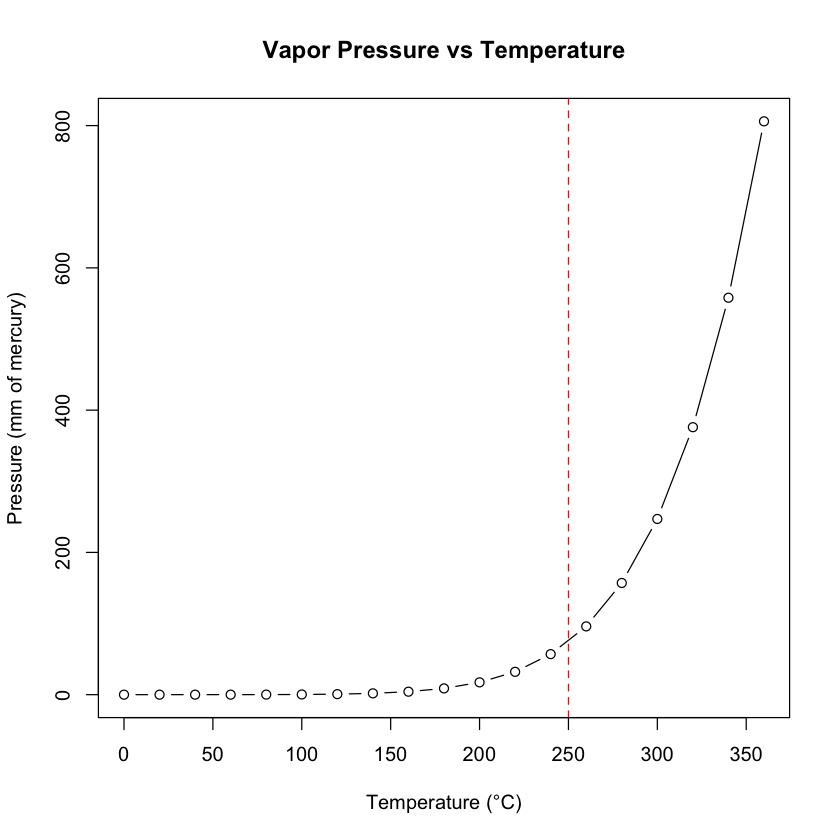

In [53]:
plot(pressure$temperature, pressure$pressure,
     type = "b",
     lty = 1,
     lwd = 1,
     main = "Vapor Pressure vs Temperature",
     xlab = "Temperature (°C)",
     ylab = "Pressure (mm of mercury)",
     pch = 1,
     cex = 1)
abline(v = 250,lty=2,col="red")


| Argument | Purpose |
|---|---|
| `type = "b"` | Draws both points and lines. |
| `type = "l"` | Draws lines only. |
| `lty` | Sets the line type. For example, `1` is solid and `2` is dashed. |
| `lwd` | Sets the line width. |
| `pch` | Sets the point shape. `1` is an empty circle and `19` is a filled circle. |
| `cex` | Changes the size of points and text. |

Run the following in the R console to see the available point shapes:

```r
?points
```

The `abline()` function adds straight lines to an existing plot. In the example above:

- `v = 250` adds a vertical line that crosses the x-axis at 250.
- `lty = 2` makes the line dashed.
- `col = "red"` sets the line colour.

To add a horizontal line, use `h` instead of `v`:

The `lines()` and `points()` functions add new layers to an existing plot. For example, the code below adds two filled blue points:

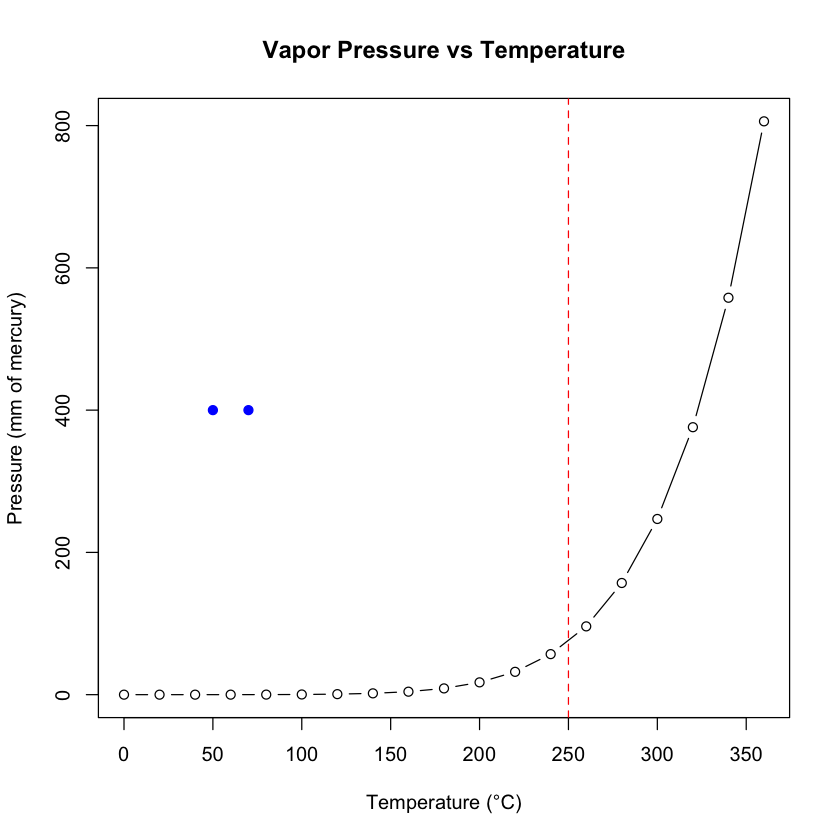

In [ ]:
points(c(50,70),c(400,400),col = 'blue',pch=19)

## Summary

- Use `par(mfrow = c(rows, columns))` to arrange multiple plots in one figure.
- Reset or restore graphical settings after using `par()`.
- Use consistent `xlim` and `ylim` values when comparing plots.
- Use `col` to control plot colours and `legend()` to explain them.
- Choose accessible palettes and do not rely on colour alone to distinguish groups.
- Use `type`, `lty`, `lwd`, `pch`, and `cex` to control the appearance of lines and points.
- Use `abline()`, `lines()`, and `points()` to add layers to an existing plot.
